# Instructions (100 Points Total: 80 Points for Coding + 20 Points for Code Demonstration and Q&A)

In this notebook you have some problems to solve with Python coding. For each problem, explain your code with comments and explain how it works to solve the problem being addressed. You also **MUST include the answers** you get from running your code. These instructions may change as needed, so we suggest you read these anew on each homework (we will try to announce ahead if they change).

Collaboration is both allowed and encouraged! Using available resources from your peers is both wise and efficient. While you are welcome to work collaboratively with classmates, that means you can work together to solve problems together, not that one person does the work and others copy it. You are also welcome to use the internet as a resource to refresh your memory, clarify concepts, and help with short code snippets. In order to model good practice, you **MUST** cite your sources **at the time of assignment submission** (we will not accept citations sent after-the-fact), and you should not be copying large portions of code wholesale from any source: internet, human, artificial intelligence, or otherwise.

Things that are off limits:
 - Soliciting (hey, what did you get for question X? Can you send me your code?) and/or copying code and/or answers from another person.
 - Using sources appropriately but failing to cite them.
 - Getting any AI, including ChatGPT, Gemini, or CoPilot to do your work for you.

You **may not** set random_state, seed, or other similar parameters manually for any library unless explicitly instructed. For numpy, you **must** use the old-style ``np.random.uniform``, ``np.random.normal``, and so on, rather than ``np.random.default_rng()`` variants.

Make sure you include **(YOUR NAME, SUBQUESTION)** (e.g. "Jane Smith, 2c") at the start of every code cell **as comment**.

**You may only use libraries that were imported for you at the top.**

**Note: All plots should have x and y axis labels, and a title at minimum, plus a legend if multiple distinct elements are present.**

# Import Statements

In [8]:
# ImportBlock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors
import scipy.stats as stats
import math
import time
import copy
from IPython.display import display

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    roc_curve, auc, confusion_matrix, classification_report,
    precision_recall_curve, accuracy_score, f1_score
)
from sklearn.svm import SVC
from sklearn.datasets import make_moons, make_circles

# Problem 1: Gradient Descent for Regression (30 Points)

In this problem, you will implement gradient descent from scratch to fit a linear regression model to a real-world dataset. You will explore how different learning rates and batch sizes affect convergence, and visualize the optimization trajectory on the loss landscape.

We will work with a synthetic housing-style dataset throughout this problem:

```py
# Dataset Generation - DO NOT MODIFY
def generate_regression_data(n_samples=1000, n_features=5, noise_std=2.0):
    X = np.random.normal(0, 1, size=(n_samples, n_features))
    true_weights = np.array([3.5, -2.0, 4.0, 0.0, -1.5])
    true_bias = 7.0
    y = X @ true_weights + true_bias + np.random.normal(0, noise_std, size=n_samples)
    return X, y, true_weights, true_bias

X_raw, y_raw, true_w, true_b = generate_regression_data()

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_raw, test_size=0.2)
```

## 1a: Loss Function and Numerical Gradient (10 Points)

Build a `LinearRegressionGD` class that computes the Mean Squared Error loss and its gradient for linear regression. The model predicts:

$$\hat{y} = X \mathbf{w} + b$$

and the loss is:

$$\mathcal{L}(\mathbf{w}, b) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Your class should match the following blueprint:

```py
class LinearRegressionGD:
    def __init__(self, n_features):
        # Initialize weights to small random values and bias to 0
        self.w = np.random.normal(0, 0.01, size=n_features)
        self.b = 0.0

    def predict(self, X):
        # Return X @ w + b
        pass

    def loss(self, X, y):
        # Compute and return the MSE loss
        pass

    def analytical_grad(self, X, y):
        # Compute the analytical gradient of the MSE w.r.t. w and b
        # dL/dw = (-2/n) * X^T @ (y - y_hat)
        # dL/db = (-2/n) * sum(y - y_hat)
        # return grad_w, grad_b
        pass

    def numerical_grad(self, X, y, h=1e-5):
        # Compute the numerical gradient using central differences
        # Perturb each element of w and b independently
        # return grad_w, grad_b
        pass
```

Once implemented:
1. Generate the dataset and create an instance of `LinearRegressionGD`.
2. Print the initial loss on the training set.
3. Compute both the analytical and numerical gradients at the initial parameters.
4. Print the maximum absolute difference between them to verify correctness.

Print results in this format:
```py
>>> Initial Training Loss: XX.XXXX
>>> Max |analytical - numerical| gradient difference: X.XXXXXXXX
```

The max gradient difference should be very small (< 1e-5). If it is not, your analytical gradient is likely incorrect.

In [9]:
# Dataset Generation - DO NOT MODIFY
def generate_regression_data(n_samples=1000, n_features=5, noise_std=2.0):
    X = np.random.normal(0, 1, size=(n_samples, n_features))
    true_weights = np.array([3.5, -2.0, 4.0, 0.0, -1.5])
    true_bias = 7.0
    y = X @ true_weights + true_bias + np.random.normal(0, noise_std, size=n_samples)
    return X, y, true_weights, true_bias

X_raw, y_raw, true_w, true_b = generate_regression_data()

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_raw, test_size=0.2)

### Implementation Guide 1a

1. **Initialize:** Set small random weights using `np.random.normal(0, 0.01, size=n_features)` and bias $b=0$.
2. **Predict:** Use matrix multiplication to compute predictions:
   $$\hat{y}=X\mathbf{w}+b$$
3. **Compute loss:** Use Mean Squared Error (MSE):
   $$L(\mathbf{w},b)=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$
4. **Analytical gradients:** Compute exact derivatives:
   - Weight gradient:
     $$\frac{\partial L}{\partial\mathbf{w}}=-\frac{2}{n}X^T(y-\hat{y})$$
   - Bias gradient:
     $$\frac{\partial L}{\partial b}=-\frac{2}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)$$
5. **Numerical gradients:** Approximate each derivative using central differences:
   $$\frac{\partial L}{\partial\theta_j}\approx\frac{L(\theta_j+h)-L(\theta_j-h)}{2h}$$
   where $\theta_j$ represents a weight or bias, and $h=10^{-5}$.
6. **Verify:** Compare analytical and numerical gradients:
   $$\text{Max Difference}=\max_j|g_j^{\text{analytical}}-g_j^{\text{numerical}}|$$
   The difference should typically be below $10^{-5}$.

**Coding decisions:**
- Use `X @ self.w + self.b` for vectorized predictions.
- Use `np.mean()` for MSE and `X.T @ error` for weight gradients.
- Perturb each parameter by $\pm h$ and restore its original value afterward.
- Apply numerical differentiation separately to weights (`w`) and bias (`b`).
- Use `np.abs()`, `np.max()`, and `max()` to verify gradient differences.

**Remember:** This step computes and verifies gradients but does not update model parameters.


### Code

In [10]:
class LinearRegressionGD:
    def __init__(self, n_features):
        # Initialize weights to small random values and bias to 0
        self.w = np.random.normal(0, 0.01, size=n_features)
        self.b = 0.0

    def predict(self, X):
        return X @ self.w + self.b # dot product with @

    def loss(self, X, y):
        y_pred = self.predict(X)
        return np.mean((y - y_pred) ** 2)

    def analytical_grad(self, X, y):
        n = len(y)
        error = y - self.predict(X)
        grad_w = (-2 / n) * (X.T @ error)
        grad_b = (-2 / n) * np.sum(error)

        return grad_w, grad_b

    def numerical_grad(self, X, y, h=1e-5):
        grad_w = np.zeros_like(self.w)

        # Numerical gradient for each weight
        for i in range(len(self.w)):
            self.w[i] += h
            loss_plus = self.loss(X, y)
            self.w[i] -= 2 * h
            loss_minus = self.loss(X, y)
            self.w[i] += h  # Restore original weight
            grad_w[i] = (loss_plus - loss_minus) / (2 * h)

        # Numerical gradient for bias
        self.b += h
        loss_plus = self.loss(X, y)
        self.b -= 2 * h
        loss_minus = self.loss(X, y)
        self.b += h  # Restore original bias
        grad_b = (loss_plus - loss_minus) / (2 * h)

        return grad_w, grad_b

In [11]:
# Create model
model = LinearRegressionGD(n_features=X_train.shape[1])

# Initial training loss
initial_loss = model.loss(X_train, y_train)

# Compute analytical and numerical gradients
grad_w_a, grad_b_a = model.analytical_grad(X_train, y_train)
grad_w_n, grad_b_n = model.numerical_grad(X_train, y_train)

# Maximum absolute difference across weights and bias
max_diff = max(
    np.max(np.abs(grad_w_a - grad_w_n)),
    abs(grad_b_a - grad_b_n)
)

print(f">>> Initial Training Loss: {initial_loss:.4f}")
print(f">>> Max |analytical - numerical| gradient difference: {max_diff:.8f}")

>>> Initial Training Loss: 88.3270
>>> Max |analytical - numerical| gradient difference: 0.00000000


## 1b: Batch Gradient Descent with ADAM (10 Points)

Add a `fit` method to your `LinearRegressionGD` class that trains the model using mini-batch gradient descent with the ADAM optimizer. Your method should follow this blueprint:

```py
def fit(self, X_train, y_train, X_test, y_test,
        n_epochs=500, batch_size=32, learning_rate=0.01,
        beta1=0.9, beta2=0.999, eps=1e-8):
    n = len(y_train)

    # Initialize ADAM moment vectors for w and b
    m_w = np.zeros_like(self.w)
    v_w = np.zeros_like(self.w)
    m_b = 0.0
    v_b = 0.0
    t_step = 0

    train_loss_history = []
    test_loss_history = []

    for epoch in range(n_epochs):
        # Shuffle training data
        indices = np.random.permutation(n)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Mini-batch loop
        for start in range(0, n, batch_size):
            # Extract batch
            # Compute analytical gradient on the batch
            # ADAM update for w and b
            t_step += 1
            # m_w = beta1 * m_w + (1 - beta1) * grad_w  (and similarly for v_w, m_b, v_b)
            # Bias correction
            # Parameter update
            pass

        # Record train and test loss at end of each epoch
        train_loss_history.append(self.loss(X_train, y_train))
        test_loss_history.append(self.loss(X_test, y_test))

    self.train_loss_history = train_loss_history
    self.test_loss_history = test_loss_history
```

After training with the default parameters:
1. Plot the train and test loss curves on the same figure (use log scale for the y-axis).
2. Print the final train and test loss.
3. Print the learned weights and bias, and compare to the true values.

```py
>>> Final Train Loss: X.XXXX
>>> Final Test Loss: X.XXXX
>>> Learned weights: [X.XX, X.XX, X.XX, X.XX, X.XX]
>>> True weights:    [3.5, -2.0, 4.0, 0.0, -1.5]
>>> Learned bias: X.XX | True bias: 7.0
```

Feel free to consult the following plotting code:
```py
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(model.train_loss_history, label='Train Loss')
ax.semilogy(model.test_loss_history, label='Test Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss (log scale)')
ax.set_title('Gradient Descent Training Curve')
ax.legend()
plt.tight_layout()
plt.show()
```

For full credit, write 2-3 sentences describing what you observe about the training curve and how close the learned parameters are to the true ones.

### Implementation Guid 1b

1. **Initialize:** Set weights and bias, and initialize first moments ($m=0$), second moments ($v=0$), and step counter ($t=0$).
2. **Shuffle and batch:** Randomly shuffle training data each epoch and divide it into mini-batches of size 32.
3. **Compute gradients:** Use `analytical_grad()` to calculate gradients $g_t$ for each mini-batch.
4. **ADAM updates:**
   - First moment (momentum):
     $$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$$
   - Second moment (squared gradients):
     $$v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$$
   - Bias correction:
     $$\hat{m}_t=\frac{m_t}{1-\beta_1^t},\qquad
     \hat{v}_t=\frac{v_t}{1-\beta_2^t}$$
   - Parameter update:
     $$\theta_{t+1}=\theta_t-\alpha\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}$$
5. **Repeat:** Update weights and bias after each mini-batch; increment $t$ for every update.
6. **Evaluate:** Record training and test MSE after each epoch.
7. **Visualize and compare:** Plot loss curves (log scale) and compare learned parameters with true values.

**Coding decisions:**
- Use `np.random.permutation()` for shuffling.
- Use array slicing for mini-batches (including the last smaller batch).
- Apply ADAM separately to weights (`w`) and bias (`b`).
- Use defaults: $\alpha=0.01$, $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$.
- Compare parameters on the same feature scale because inputs were standardized.

### Code

In [13]:
def fit(self, X_train, y_train, X_test, y_test,
        n_epochs=500, batch_size=32, learning_rate=0.01,
        beta1=0.9, beta2=0.999, eps=1e-8):

    n = len(y_train) # number of samples in training set

    # Initialize ADAM moment vectors
    m_w = np.zeros_like(self.w)
    v_w = np.zeros_like(self.w)
    m_b = 0.0
    v_b = 0.0
    t_step = 0

    train_loss_history = []
    test_loss_history = []

    for epoch in range(n_epochs):
        # Shuffle training data
        indices = np.random.permutation(n)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Mini-batch loop
        for start in range(0, n, batch_size):
            # Extract batch
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            # Compute analytical gradients
            grad_w, grad_b = self.analytical_grad(X_batch, y_batch)

            # ADAM update
            t_step += 1

            # First moment (momentum)
            m_w = beta1 * m_w + (1 - beta1) * grad_w
            m_b = beta1 * m_b + (1 - beta1) * grad_b

            # Second moment (squared gradients)
            v_w = beta2 * v_w + (1 - beta2) * grad_w**2
            v_b = beta2 * v_b + (1 - beta2) * grad_b**2

            # Bias correction
            m_w_hat = m_w / (1 - beta1**t_step)
            m_b_hat = m_b / (1 - beta1**t_step)
            v_w_hat = v_w / (1 - beta2**t_step)
            v_b_hat = v_b / (1 - beta2**t_step)

            # Update parameters
            self.w -= learning_rate * m_w_hat / (np.sqrt(v_w_hat) + eps)
            self.b -= learning_rate * m_b_hat / (np.sqrt(v_b_hat) + eps)

        # Record loss after each epoch
        train_loss_history.append(self.loss(X_train, y_train))
        test_loss_history.append(self.loss(X_test, y_test))

    self.train_loss_history = train_loss_history
    self.test_loss_history = test_loss_history

# Attach the function as a class method
LinearRegressionGD.fit = fit

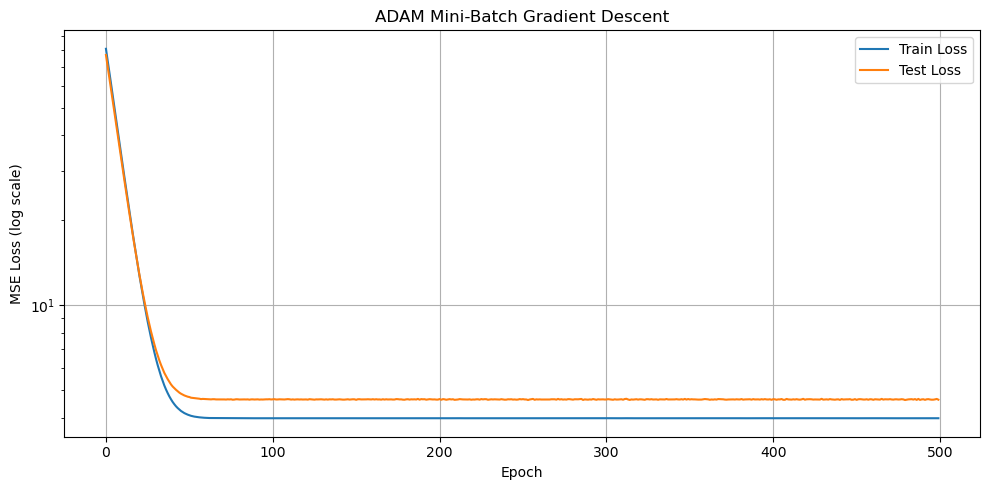

>>> Final Train Loss: 3.9772
>>> Final Test Loss: 4.6271
 
>>> Learned weights: [ 3.49 -1.96  4.18 -0.07 -1.46]
>>> True weights (scaled features): [ 3.49 -2.04  4.16  0.   -1.5 ]
>>> Learned bias: 7.02 | True bias (scaled features): 6.98
 
>>> Learned weights (converted into original scale): [ 3.5  -1.92  4.02 -0.07 -1.46]
>>> True weights (original scale): [ 3.5 -2.   4.   0.  -1.5]
>>> Learned bias (converted into original scale): 7.04 | True bias: 7.0


In [20]:
# Initialize and train
model = LinearRegressionGD(n_features=X_train.shape[1])

model.fit(X_train, y_train, X_test, y_test)

# Plot training and testing loss
fig, ax = plt.subplots(figsize=(10, 5))

ax.semilogy(model.train_loss_history, label='Train Loss')
ax.semilogy(model.test_loss_history, label='Test Loss')

ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss (log scale)')
ax.set_title('ADAM Mini-Batch Gradient Descent')
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

# Final losses
print(f">>> Final Train Loss: {model.train_loss_history[-1]:.4f}")
print(f">>> Final Test Loss: {model.test_loss_history[-1]:.4f}")

print(' ')
# Compare learned and true parameters
print(f">>> Learned weights: {np.round(model.w, 2)}")

# Account for feature standardization
true_w_scaled = true_w * scaler.scale_
true_b_scaled = true_b + scaler.mean_ @ true_w

print(f">>> True weights (scaled features): {np.round(true_w_scaled, 2)}")
print(f">>> Learned bias: {model.b:.2f} | True bias (scaled features): {true_b_scaled:.2f}")

# Convert learned parameters back to original feature scale
w_original = model.w / scaler.scale_
b_original = model.b - scaler.mean_ @ w_original

print(' ')
print(f">>> Learned weights (converted into original scale): {np.round(w_original, 2)}")
print(f">>> True weights (original scale): {true_w}")
print(f">>> Learned bias (converted into original scale): {b_original:.2f} | True bias: {true_b:.1f}")

*[Your written response here]*

## 1c: Sensitivity Analysis (10 Points)

Investigate how the learning rate and batch size affect convergence.

For learning rates in `[0.0001, 0.001, 0.005, 0.01, 0.05, 0.1]` and batch sizes in `[16, 32, 64, 128, 256, 800]`:
- Train a fresh `LinearRegressionGD` model for `n_epochs=200` with each combination.
- Record the final test loss.

Produce a heatmap (using `plt.pcolormesh`) of the final test loss across the grid of (learning_rate x batch_size). Use a log color scale (`norm=matplotlib.colors.LogNorm()`).

Print the best combination found:
```py
>>> Best: lr=X.XXXX, batch_size=XXX -> Test Loss: X.XXXXXX
```

Feel free to consult the following plotting code:
```py
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1]
batch_sizes = [16, 32, 64, 128, 256, 800]

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.pcolormesh(loss_grid, norm=matplotlib.colors.LogNorm(), cmap='viridis')
fig.colorbar(im, label='Final Test Loss (log scale)')

for i in range(len(learning_rates)):
    for j in range(len(batch_sizes)):
        ax.text(j + 0.5, i + 0.5, f"{loss_grid[i, j]:.2e}",
                ha='center', va='center', color='red', fontsize=9, fontweight='bold')

ax.set_xticks(np.arange(len(batch_sizes)) + 0.5)
ax.set_xticklabels(batch_sizes)
ax.set_yticks(np.arange(len(learning_rates)) + 0.5)
ax.set_yticklabels(learning_rates)
ax.set_xlabel('Batch Size')
ax.set_ylabel('Learning Rate')
ax.set_title('Sensitivity Analysis: Final Test Loss')
plt.tight_layout()
plt.show()

best_idx = np.unravel_index(np.argmin(loss_grid), loss_grid.shape)
print(f"Best: lr={learning_rates[best_idx[0]]}, batch_size={batch_sizes[best_idx[1]]} -> Test Loss: {loss_grid[best_idx]:.6f}")
```

For full credit, write 2-3 sentences interpreting the heatmap. What trends do you see with respect to learning rate and batch size? Are there any combinations that fail to converge?

### Implementation Guide 1c

1. **Define hyperparameters:** Use 6 learning rates and 6 batch sizes, giving $6\times6=36$ combinations.
2. **Initialize:** Create `loss_grid` with shape `(6, 6)` to store final test losses.
3. **Train:** For each combination, initialize a fresh `LinearRegressionGD` model and train for 200 epochs using ADAM.
4. **Evaluate:** Record the final test MSE in `loss_grid[i, j]`.
5. **Visualize:** Use `plt.pcolormesh()` with `matplotlib.colors.LogNorm()` to display the loss heatmap.
6. **Select:** Find the combination with the lowest test loss using `np.argmin()` and `np.unravel_index()`.

**Coding decisions:**
- Use nested loops to explore all hyperparameter combinations.
- Initialize a new model for each experiment to avoid carrying over learned parameters.
- Use the same training and test data for fair comparison.
- Use a logarithmic color scale to highlight differences in loss.
- Use `ax.text()` to annotate each heatmap cell.


In [21]:
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1]
batch_sizes = [16, 32, 64, 128, 256, 800]

# Initialize loss grid: rows = learning rates, columns = batch sizes
loss_grid = np.zeros((len(learning_rates), len(batch_sizes)))

for i, lr in enumerate(learning_rates):
    for j, bs in enumerate(batch_sizes):

        # Fresh model for each combination
        model = LinearRegressionGD(n_features=X_train.shape[1])

        # Train using ADAM
        model.fit(
            X_train, y_train, X_test, y_test,
            n_epochs=200,
            batch_size=bs,
            learning_rate=lr
        )

        # Record final test loss
        loss_grid[i, j] = model.test_loss_history[-1]

        print(f"lr={lr:.4f}, batch_size={bs:3d}, "
              f"Test Loss={loss_grid[i, j]:.6f}")


lr=0.0001, batch_size= 16, Test Loss=58.939330
lr=0.0001, batch_size= 32, Test Loss=69.891767
lr=0.0001, batch_size= 64, Test Loss=76.137075
lr=0.0001, batch_size=128, Test Loss=79.498427
lr=0.0001, batch_size=256, Test Loss=81.385256
lr=0.0001, batch_size=800, Test Loss=83.160420
lr=0.0010, batch_size= 16, Test Loss=4.651812
lr=0.0010, batch_size= 32, Test Loss=12.093578
lr=0.0010, batch_size= 64, Test Loss=30.862312
lr=0.0010, batch_size=128, Test Loss=49.051060
lr=0.0010, batch_size=256, Test Loss=61.882405
lr=0.0010, batch_size=800, Test Loss=77.609269
lr=0.0050, batch_size= 16, Test Loss=4.639666
lr=0.0050, batch_size= 32, Test Loss=4.633633
lr=0.0050, batch_size= 64, Test Loss=4.672521
lr=0.0050, batch_size=128, Test Loss=7.823416
lr=0.0050, batch_size=256, Test Loss=18.783737
lr=0.0050, batch_size=800, Test Loss=56.526203
lr=0.0100, batch_size= 16, Test Loss=4.639246
lr=0.0100, batch_size= 32, Test Loss=4.649100
lr=0.0100, batch_size= 64, Test Loss=4.637458
lr=0.0100, batch_size

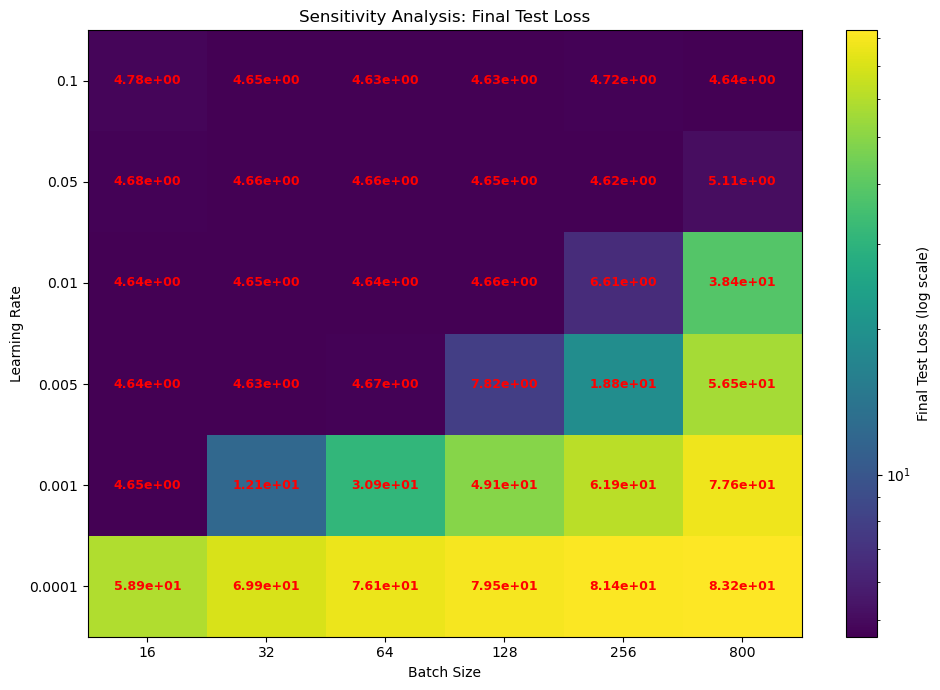

>>> Best: lr=0.0500, batch_size=256 -> Test Loss: 4.616776


In [22]:
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.pcolormesh(
    loss_grid,
    norm=matplotlib.colors.LogNorm(),
    cmap='viridis'
)

fig.colorbar(im, label='Final Test Loss (log scale)')

# Annotate each cell
for i in range(len(learning_rates)):
    for j in range(len(batch_sizes)):
        ax.text(
            j + 0.5, i + 0.5,
            f"{loss_grid[i, j]:.2e}",
            ha='center', va='center',
            color='red', fontsize=9,
            fontweight='bold'
        )

ax.set_xticks(np.arange(len(batch_sizes)) + 0.5)
ax.set_xticklabels(batch_sizes)

ax.set_yticks(np.arange(len(learning_rates)) + 0.5)
ax.set_yticklabels(learning_rates)

ax.set_xlabel('Batch Size')
ax.set_ylabel('Learning Rate')
ax.set_title('Sensitivity Analysis: Final Test Loss')

plt.tight_layout()
plt.show()

# Find best combination
best_idx = np.unravel_index(np.argmin(loss_grid), loss_grid.shape)

best_lr = learning_rates[best_idx[0]]
best_bs = batch_sizes[best_idx[1]]
best_loss = loss_grid[best_idx]

print(f">>> Best: lr={best_lr:.4f}, "
      f"batch_size={best_bs} -> Test Loss: {best_loss:.6f}")

*[Your written response here]*

# Problem 2: Regularized Regression (20 Points)

In this problem, you will extend your gradient descent implementation to include L1 (Lasso), L2 (Ridge), and ElasticNet regularization. You will explore how regularization affects model coefficients and use cross-validation to select the best hyperparameters.

We will use a dataset with many features, some of which are irrelevant, to see how regularization helps:

```py
# Dataset Generation - DO NOT MODIFY
def generate_sparse_data(n_samples=500, n_features=50, n_informative=5, noise_std=1.0):
    X = np.random.normal(0, 1, size=(n_samples, n_features))
    true_weights = np.zeros(n_features)
    informative_idx = np.array([0, 5, 12, 23, 41])
    true_weights[informative_idx] = np.array([4.0, -3.0, 2.5, -1.5, 3.0])
    true_bias = 5.0
    y = X @ true_weights + true_bias + np.random.normal(0, noise_std, size=n_samples)
    return X, y, true_weights, true_bias, informative_idx

X_sparse, y_sparse, true_w_sparse, true_b_sparse, info_idx = generate_sparse_data()

# Standardize features
scaler2 = StandardScaler()
X_sparse_scaled = scaler2.fit_transform(X_sparse)

# Train/test split (80/20)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_sparse_scaled, y_sparse, test_size=0.2)
```

## 2a: Regularized Gradient Descent (10 Points)

Create a `RegularizedRegressionGD` class that extends your gradient descent approach to include regularization. The regularized loss is:

$$\mathcal{L}(\mathbf{w}, b) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \left[ \rho \|\mathbf{w}\|_1 + \frac{1 - \rho}{2} \|\mathbf{w}\|_2^2 \right]$$

where $\alpha$ controls regularization strength and $\rho$ controls the L1/L2 mix ($\rho = 1$ is Lasso, $\rho = 0$ is Ridge, $0 < \rho < 1$ is ElasticNet).

Your class should follow this blueprint:

```py
class RegularizedRegressionGD:
    def __init__(self, n_features, alpha=0.1, rho=0.5):
        # Initialize weights to small random values and bias to 0
        self.w = np.random.normal(0, 0.01, size=n_features)
        self.b = 0.0
        self.alpha = alpha
        self.rho = rho  # 1.0 = Lasso, 0.0 = Ridge

    def predict(self, X):
        pass

    def loss(self, X, y):
        # MSE + regularization penalty
        # Note: bias is NOT regularized
        pass

    def grad(self, X, y):
        # Analytical gradient of the regularized loss
        # L2 gradient contribution: alpha * (1 - rho) * w
        # L1 gradient contribution: alpha * rho * sign(w)
        # return grad_w, grad_b
        pass

    def fit(self, X_train, y_train, X_test, y_test,
            n_epochs=500, batch_size=32, learning_rate=0.01,
            beta1=0.9, beta2=0.999, eps=1e-8):
        # Same ADAM optimizer loop as Problem 1b,
        # but using the regularized gradient
        # Store self.train_loss_history and self.test_loss_history
        pass
```

Once implemented, train three models on the sparse dataset:
1. **Ridge** ($\rho = 0.0$, $\alpha = 0.1$)
2. **Lasso** ($\rho = 1.0$, $\alpha = 0.1$)
3. **ElasticNet** ($\rho = 0.5$, $\alpha = 0.1$)

For each model:
- Plot the learned weight vector as a bar chart (all 50 features on the x-axis, weight magnitude on the y-axis). Highlight the 5 informative features in a different color.
- Print the test loss and the number of "near-zero" weights (|w| < 0.05).

```py
>>> [Ridge]      Test Loss: X.XXXX | Near-zero weights: XX/50
>>> [Lasso]      Test Loss: X.XXXX | Near-zero weights: XX/50
>>> [ElasticNet] Test Loss: X.XXXX | Near-zero weights: XX/50
```

Feel free to consult the following plotting code:
```py
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
labels = ['Ridge (rho=0)', 'Lasso (rho=1)', 'ElasticNet (rho=0.5)']
models = [model_ridge, model_lasso, model_elastic]

for ax, model, label in zip(axes, models, labels):
    colors = ['tab:orange' if i in info_idx else 'tab:blue' for i in range(len(model.w))]
    ax.bar(range(len(model.w)), model.w, color=colors)
    ax.set_xlabel('Feature Index')
    ax.set_title(label)
    ax.axhline(0, color='black', linewidth=0.5)

axes[0].set_ylabel('Weight Value')
fig.suptitle('Learned Weights Under Different Regularization', fontsize=13)
plt.tight_layout()
plt.show()
```

For full credit, write 3-4 sentences comparing how Ridge, Lasso, and ElasticNet handle the irrelevant features. Which method(s) drive the irrelevant weights closest to zero?

### Implementation Guide 2a

1. **Initialize:** Set small random weights, bias $b=0$, regularization strength $\alpha=0.1$, and mixing ratio $\rho$.
2. **Predict:** Use $\hat y=X\mathbf w+b$.
3. **Compute loss:** Add regularization to MSE:
   $$\mathcal L=\text{MSE}+\alpha\left[\rho\|\mathbf w\|_1+\frac{1-\rho}{2}\|\mathbf w\|_2^2\right]$$
4. **Compute gradients:** Add L1 and L2 contributions to the weight gradient:
   $$\nabla_{\mathbf w}\mathcal L=-\frac2nX^T(y-\hat y)+\alpha\rho\,\operatorname{sign}(\mathbf w)+\alpha(1-\rho)\mathbf w$$
   The bias gradient is unchanged.
5. **Train:** Reuse mini-batch ADAM from Problem 1b, replacing `analytical_grad()` with `grad()`.
6. **Compare:** Train Ridge ($\rho=0$), Lasso ($\rho=1$), and ElasticNet ($\rho=0.5$), all with $\alpha=0.1$.
7. **Evaluate:** Print test loss and count weights satisfying $|w_j|<0.05$.
8. **Visualize:** Plot all 50 coefficients, highlighting the 5 informative features.

**Coding decisions:**
- Use `np.abs()` and `np.sum()` for the L1 penalty.
- Use `np.sign()` for the L1 subgradient and `self.w` for the L2 gradient.
- Do not regularize the bias.
- Use identical ADAM settings for all three models.
- Use `ax.bar()` and different colors to distinguish informative and irrelevant features.


In [23]:
# Dataset Generation - DO NOT MODIFY
def generate_sparse_data(n_samples=500, n_features=50, n_informative=5, noise_std=1.0):
    X = np.random.normal(0, 1, size=(n_samples, n_features))
    true_weights = np.zeros(n_features)
    informative_idx = np.array([0, 5, 12, 23, 41])
    true_weights[informative_idx] = np.array([4.0, -3.0, 2.5, -1.5, 3.0])
    true_bias = 5.0
    y = X @ true_weights + true_bias + np.random.normal(0, noise_std, size=n_samples)
    return X, y, true_weights, true_bias, informative_idx

X_sparse, y_sparse, true_w_sparse, true_b_sparse, info_idx = generate_sparse_data()

# Standardize features
scaler2 = StandardScaler()
X_sparse_scaled = scaler2.fit_transform(X_sparse)

# Train/test split (80/20)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_sparse_scaled, y_sparse, test_size=0.2)

In [36]:
class RegularizedRegressionGD:
    def __init__(self, n_features, alpha=0.1, rho=0.5):
        # self.w = np.random.normal(0, 0.01, size=n_features)
        self.w = np.full(n_features, 0.1) # uncomment this line to compare diff regularization at the same start point
        self.b = 0.0
        self.alpha = alpha
        self.rho = rho

    def predict(self, X):
        return X @ self.w + self.b

    def loss(self, X, y):
        mse = np.mean((y - self.predict(X)) ** 2)
        l1 = np.sum(np.abs(self.w))
        l2 = np.sum(self.w ** 2)
        penalty = self.alpha * (
            self.rho * l1 + (1 - self.rho) / 2 * l2
        )
        return mse + penalty

    def grad(self, X, y):
        n = len(y)
        error = y - self.predict(X)
        # MSE gradients
        grad_w = (-2 / n) * (X.T @ error)
        grad_b = (-2 / n) * np.sum(error)
        # Regularization gradients (weights only)
        grad_w += self.alpha * (
            self.rho * np.sign(self.w)
            + (1 - self.rho) * self.w
        )
        return grad_w, grad_b

    def fit(self, X_train, y_train, X_test, y_test,
            n_epochs=500, batch_size=32, learning_rate=0.01,
            beta1=0.9, beta2=0.999, eps=1e-8):

        n = len(y_train)
        # Initialize ADAM moments
        m_w = np.zeros_like(self.w)
        v_w = np.zeros_like(self.w)
        m_b = 0.0
        v_b = 0.0
        t_step = 0

        train_loss_history = []
        test_loss_history = []

        for epoch in range(n_epochs):

            # Shuffle training data
            indices = np.random.permutation(n)
            X_shuffled = X_train[indices]
            y_shuffled = y_train[indices]

            # Mini-batch gradient descent
            for start in range(0, n, batch_size):
                X_batch = X_shuffled[start:start + batch_size]
                y_batch = y_shuffled[start:start + batch_size]

                # Regularized gradients
                grad_w, grad_b = self.grad(X_batch, y_batch)

                t_step += 1

                # First moments
                m_w = beta1 * m_w + (1 - beta1) * grad_w
                m_b = beta1 * m_b + (1 - beta1) * grad_b

                # Second moments
                v_w = beta2 * v_w + (1 - beta2) * grad_w**2
                v_b = beta2 * v_b + (1 - beta2) * grad_b**2

                # Bias correction
                m_w_hat = m_w / (1 - beta1**t_step)
                m_b_hat = m_b / (1 - beta1**t_step)
                v_w_hat = v_w / (1 - beta2**t_step)
                v_b_hat = v_b / (1 - beta2**t_step)

                # Parameter updates
                self.w -= learning_rate * m_w_hat / (np.sqrt(v_w_hat) + eps)
                self.b -= learning_rate * m_b_hat / (np.sqrt(v_b_hat) + eps)

            # Record loss after each epoch
            train_loss_history.append(self.loss(X_train, y_train))
            test_loss_history.append(self.loss(X_test, y_test))

        self.train_loss_history = train_loss_history
        self.test_loss_history = test_loss_history

In [37]:
# Initialize models
model_ridge = RegularizedRegressionGD(
    n_features=50, alpha=0.1, rho=0.0
)

model_lasso = RegularizedRegressionGD(
    n_features=50, alpha=0.1, rho=1.0
)

model_elastic = RegularizedRegressionGD(
    n_features=50, alpha=0.1, rho=0.5
)

models = [model_ridge, model_lasso, model_elastic]
names = ['Ridge', 'Lasso', 'ElasticNet']

# Train and evaluate
for name, model in zip(names, models):

    model.fit(X_train2, y_train2, X_test2, y_test2)

    test_loss = model.loss(X_test2, y_test2)
    near_zero = np.sum(np.abs(model.w) < 0.05)
    test_mse = np.mean((y_test2 - model.predict(X_test2)) ** 2)

    print(f">>> [{name:<10}] Test Loss: {test_mse:.4f} | "
          f">>> [{name:<10}] Test Loss + w penalty: {test_loss:.4f} | "
          f"Near-zero weights: {near_zero}/50")

>>> [Ridge     ] Test Loss: 0.8399 | >>> [Ridge     ] Test Loss + w penalty: 2.7403 | Near-zero weights: 23/50
>>> [Lasso     ] Test Loss: 0.7976 | >>> [Lasso     ] Test Loss + w penalty: 2.2399 | Near-zero weights: 42/50
>>> [ElasticNet] Test Loss: 0.7641 | >>> [ElasticNet] Test Loss + w penalty: 2.4893 | Near-zero weights: 37/50


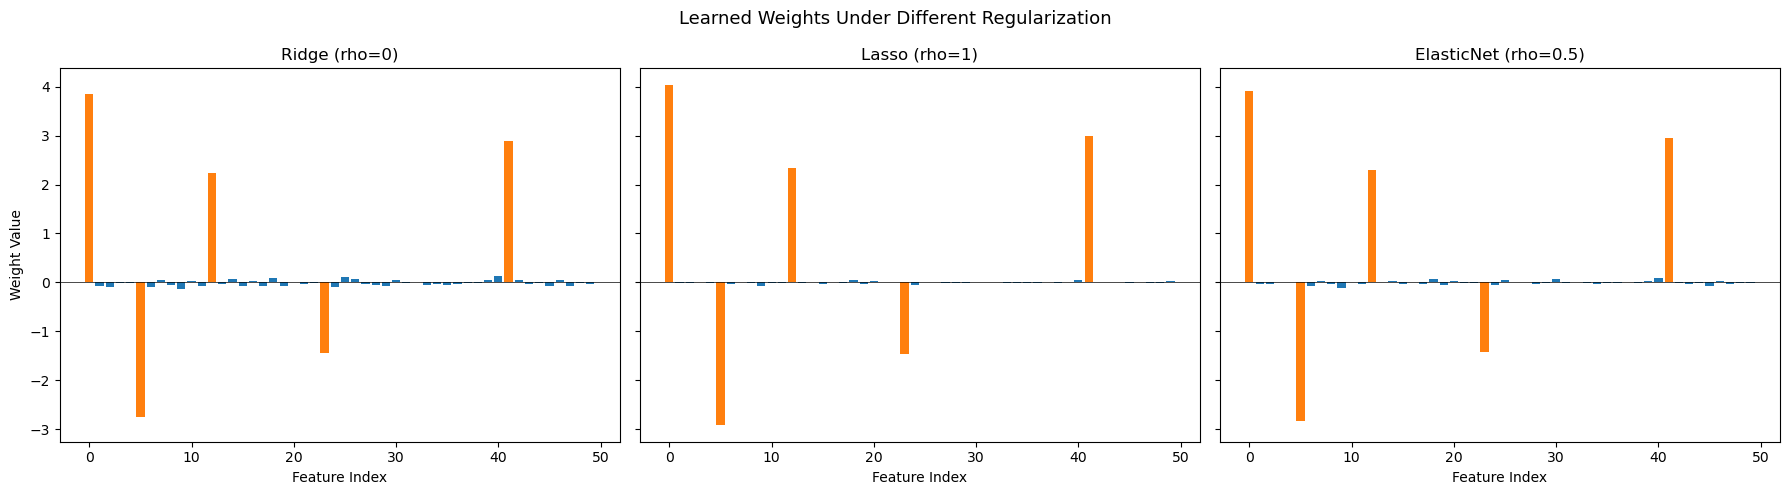

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

labels = [
    'Ridge (rho=0)',
    'Lasso (rho=1)',
    'ElasticNet (rho=0.5)'
]

for ax, model, label in zip(axes, models, labels):

    colors = [
        'tab:orange' if i in info_idx else 'tab:blue'
        for i in range(len(model.w))
    ]

    ax.bar(range(len(model.w)), model.w, color=colors)
    ax.set_xlabel('Feature Index')
    ax.set_title(label)
    ax.axhline(0, color='black', linewidth=0.5)

axes[0].set_ylabel('Weight Value')
fig.suptitle(
    'Learned Weights Under Different Regularization',
    fontsize=13
)

plt.tight_layout()
plt.show()

*[Your written response here]*

## 2b: Regularization Path (10 Points)

A regularization path shows how the model coefficients change as the regularization strength $\alpha$ varies. This helps us understand the tradeoff between model complexity and regularization.

For **Lasso** ($\rho = 1.0$), sweep $\alpha$ over `np.logspace(-4, 1, 30)` (30 values from 0.0001 to 10). For each $\alpha$, train a fresh `RegularizedRegressionGD` model with `n_epochs=300` and `learning_rate=0.01`. Record the learned weight vector.

Produce a plot where:
- The x-axis is $\alpha$ (log scale).
- The y-axis is the weight value.
- Each of the 50 features is a separate line.
- The 5 informative features are plotted with thicker, distinctly colored lines and labeled in the legend.
- The remaining 45 features are plotted with thin gray lines (no individual legend entries).

Feel free to consult the following plotting code:
```py
alphas = np.logspace(-4, 1, 30)
# weight_paths should be shape (30, 50)

fig, ax = plt.subplots(figsize=(12, 6))
for j in range(weight_paths.shape[1]):
    if j in info_idx:
        ax.plot(alphas, weight_paths[:, j], linewidth=2.5,
                label=f'Feature {j} (true w={true_w_sparse[j]:.1f})')
    else:
        ax.plot(alphas, weight_paths[:, j], color='gray', alpha=0.3, linewidth=0.8)

ax.set_xscale('log')
ax.set_xlabel('Alpha (log scale)')
ax.set_ylabel('Weight Value')
ax.set_title('Lasso Regularization Path')
ax.axhline(0, color='black', linewidth=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
```

For full credit, write 2-3 sentences describing what happens to the informative vs. non-informative weights as $\alpha$ increases.

### Implementation Guide 2b

1. **Define regularization strengths:** Use `np.logspace(-4, 1, 30)` to generate 30 values of $\alpha$ from $10^{-4}$ to $10^1$.
2. **Initialize:** Create `weight_paths` with shape `(30, 50)` to store learned coefficients.
3. **Train:** For each $\alpha$, initialize a fresh Lasso model ($\rho=1$) and train for 300 epochs using ADAM with learning rate $0.01$.
4. **Record:** Store the learned weight vector in `weight_paths[i, :]`.
5. **Visualize:** Plot each feature's weight against $\alpha$ using a logarithmic x-axis.
6. **Compare:** Observe how informative and irrelevant feature weights change as regularization increases.

**Coding decisions:**
- Use `np.logspace()` to explore regularization strengths across several orders of magnitude.
- Use identical initial weights and `np.random.seed(42)` before each training run for a controlled comparison.
- Use `model.w.copy()` to record weights independently.
- Highlight the 5 informative features with thick colored lines and labels.
- Plot the remaining 45 features as thin gray lines without legend entries.
- Use `ax.set_xscale('log')` for the regularization path.


In [39]:
# Regularization strengths
alphas = np.logspace(-4, 1, 30)

# Store learned weights: 30 alpha values x 50 features
weight_paths = np.zeros((len(alphas), X_train2.shape[1]))

# Use identical initial weights and mini-batch order
initial_w = np.full(X_train2.shape[1], 0.1)

for i, alpha in enumerate(alphas):

    # Fresh Lasso model
    model = RegularizedRegressionGD(
        n_features=X_train2.shape[1],
        alpha=alpha,
        rho=1.0
    )

    model.w = initial_w.copy()
    model.b = 0.0

    # Same random shuffling for each run
    np.random.seed(42)

    # Train model
    model.fit(
        X_train2, y_train2, X_test2, y_test2,
        n_epochs=300,
        learning_rate=0.01
    )

    # Record learned weights
    weight_paths[i, :] = model.w.copy()

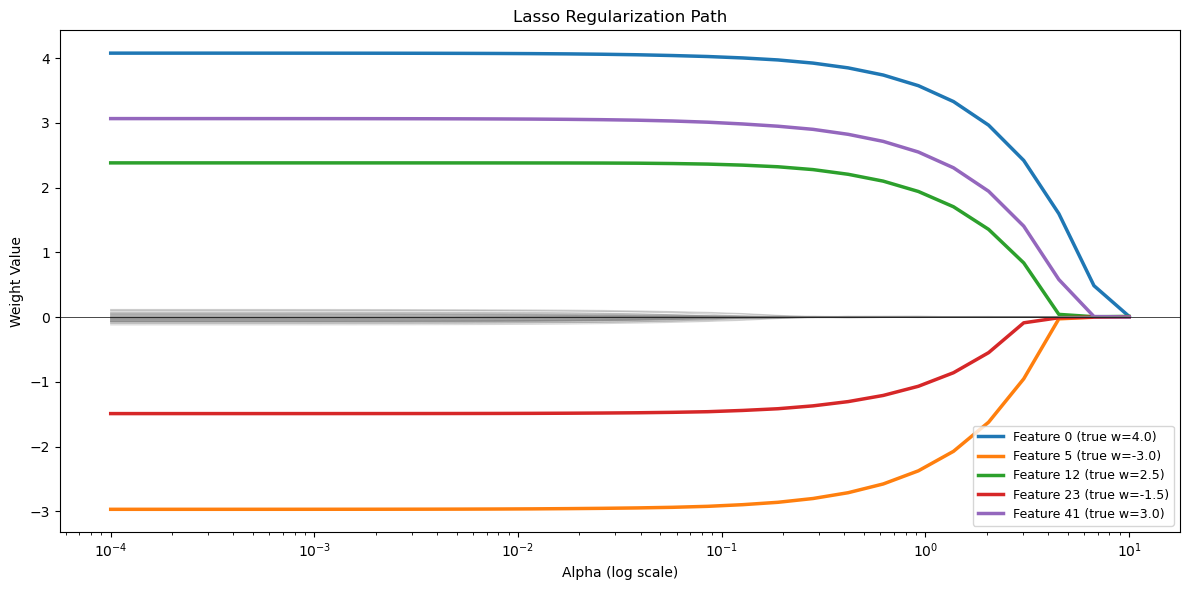

In [40]:
fig, ax = plt.subplots(figsize=(12, 6))

for j in range(weight_paths.shape[1]):

    if j in info_idx:
        ax.plot(
            alphas, weight_paths[:, j],
            linewidth=2.5,
            label=f'Feature {j} (true w={true_w_sparse[j]:.1f})'
        )
    else:
        ax.plot(
            alphas, weight_paths[:, j],
            color='gray',
            alpha=0.3,
            linewidth=0.8
        )

ax.set_xscale('log')
ax.set_xlabel('Alpha (log scale)')
ax.set_ylabel('Weight Value')
ax.set_title('Lasso Regularization Path')
ax.axhline(0, color='black', linewidth=0.5)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

*[Your written response here]*

## 2c: Cross-Validated Hyperparameter Selection (10 Points)

Use 5-fold cross-validation to select the best $\alpha$ and $\rho$ for the ElasticNet model on the sparse dataset.

For $\alpha$ in `[0.001, 0.01, 0.05, 0.1, 0.5, 1.0]` and $\rho$ in `[0.0, 0.25, 0.5, 0.75, 1.0]`:
- For each of 5 folds, train a `RegularizedRegressionGD` model with `n_epochs=300`, `learning_rate=0.01` and score the held-out fold.
- Record the mean cross-validation MSE across the 5 folds.

You should use `sklearn.model_selection.KFold` with `n_splits=5` and `shuffle=True`.

Produce a heatmap of the mean CV loss across the ($\alpha$ x $\rho$) grid. Print the best combination:
```py
>>> Best CV: alpha=X.XXX, rho=X.XX -> Mean CV Loss: X.XXXXXX
```

Then, train a final model with the best hyperparameters on the full training set and report:
```py
>>> Final model Test Loss: X.XXXX
>>> Number of near-zero weights (|w| < 0.05): XX/50
```

Feel free to consult the following plotting code:
```py
alphas_cv = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
rhos_cv = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.pcolormesh(cv_loss_grid, norm=matplotlib.colors.LogNorm(), cmap='viridis')
fig.colorbar(im, label='Mean CV Loss (log scale)')

for i in range(len(alphas_cv)):
    for j in range(len(rhos_cv)):
        ax.text(j + 0.5, i + 0.5, f"{cv_loss_grid[i, j]:.3f}",
                ha='center', va='center', color='red', fontsize=10, fontweight='bold')

ax.set_xticks(np.arange(len(rhos_cv)) + 0.5)
ax.set_xticklabels(rhos_cv)
ax.set_yticks(np.arange(len(alphas_cv)) + 0.5)
ax.set_yticklabels(alphas_cv)
ax.set_xlabel('Rho (L1/L2 Mix)')
ax.set_ylabel('Alpha (Regularization Strength)')
ax.set_title('Cross-Validation: Mean Test Loss')
plt.tight_layout()
plt.show()
```

For full credit, write 2-3 sentences on what the cross-validation results tell you about the best regularization strategy for this dataset.

### Implementation Guide 2c

1. **Define hyperparameters:** Use 6 values of $\alpha$ and 5 values of $\rho$, giving $6\times5=30$ combinations.
2. **Initialize:** Create `cv_loss_grid` with shape `(6, 5)` to store mean validation MSE.
3. **Split:** Use `KFold(n_splits=5, shuffle=True)` to generate 5 training/validation splits.
4. **Train:** For each $(\alpha,\rho)$ and each fold, initialize a fresh `RegularizedRegressionGD` model and train for 300 epochs using ADAM.
5. **Evaluate:** Compute validation MSE without regularization penalty:
   $$\text{MSE}_{\text{val}}=\frac{1}{n_{\text{val}}}\sum_{i=1}^{n_{\text{val}}}(y_i-\hat y_i)^2$$
6. **Average:** Calculate the mean MSE across 5 folds:
   $$\text{CV MSE}=\frac{1}{5}\sum_{k=1}^{5}\text{MSE}_k$$
7. **Visualize:** Use `plt.pcolormesh()` with `LogNorm()` to display the CV loss heatmap.
8. **Select and retrain:** Find the best $(\alpha,\rho)$ using `np.argmin()`, retrain on the full training set, and evaluate on the held-out test set.

**Coding decisions:**
- Use `KFold` with a fixed random state for reproducible splits.
- Use identical initial weights and consistent mini-batch shuffling for fair comparisons.
- Use `model.predict()` to calculate validation MSE, excluding the regularization penalty.
- Use `np.mean()` to average validation losses across folds.
- Use `np.unravel_index()` to identify the best hyperparameter combination.
- Keep `X_test2` out of hyperparameter selection.


In [44]:
alphas_cv = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
rhos_cv = [0.0, 0.25, 0.5, 0.75, 1.0]

# Initialize CV loss grid
cv_loss_grid = np.zeros((len(alphas_cv), len(rhos_cv)))

# 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True)

for i, alpha in enumerate(alphas_cv):
    for j, rho in enumerate(rhos_cv):

        fold_losses = []

        for fold, (train_idx, val_idx) in enumerate(kf.split(X_train2)):

            # Split training data into training and validation folds
            X_tr = X_train2[train_idx]
            y_tr = y_train2[train_idx]
            X_val = X_train2[val_idx]
            y_val = y_train2[val_idx]

            # Fresh model with identical initialization
            model = RegularizedRegressionGD(
                n_features=X_train2.shape[1],
                alpha=alpha,
                rho=rho
            )
            model.w = np.full(X_train2.shape[1], 0.1)
            model.b = 0.0

            # Reproducible mini-batch shuffling
            np.random.seed(42 + fold)

            # Train model
            model.fit(
                X_tr, y_tr, X_val, y_val,
                n_epochs=300,
                learning_rate=0.01
            )

            # Validation MSE (without regularization penalty)
            val_mse = np.mean((y_val - model.predict(X_val)) ** 2)
            fold_losses.append(val_mse)

        # Average MSE across 5 folds
        cv_loss_grid[i, j] = np.mean(fold_losses)

# Find best hyperparameters
best_idx = np.unravel_index(np.argmin(cv_loss_grid), cv_loss_grid.shape)

best_alpha = alphas_cv[best_idx[0]]
best_rho = rhos_cv[best_idx[1]]
best_cv_loss = cv_loss_grid[best_idx]

print(f">>> Best CV: alpha={best_alpha:.3f}, "
      f"rho={best_rho:.2f} -> Mean CV Loss: {best_cv_loss:.6f}")

>>> Best CV: alpha=0.100, rho=1.00 -> Mean CV Loss: 1.091666


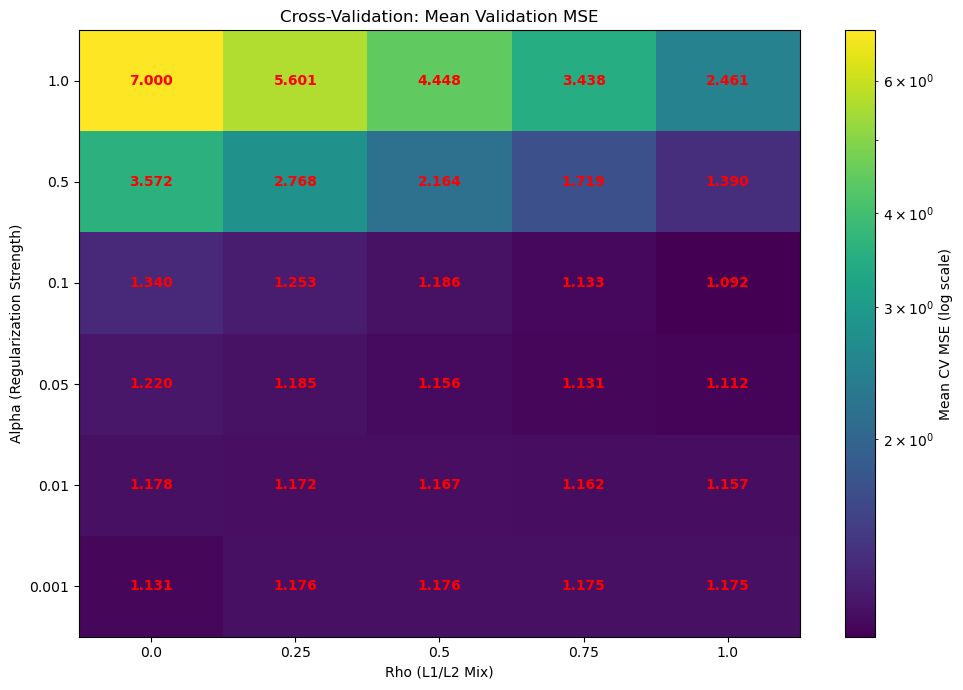

In [45]:
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.pcolormesh(
    cv_loss_grid,
    norm=matplotlib.colors.LogNorm(),
    cmap='viridis'
)

fig.colorbar(im, label='Mean CV MSE (log scale)')

for i in range(len(alphas_cv)):
    for j in range(len(rhos_cv)):
        ax.text(
            j + 0.5, i + 0.5,
            f"{cv_loss_grid[i, j]:.3f}",
            ha='center', va='center',
            color='red', fontsize=10,
            fontweight='bold'
        )

ax.set_xticks(np.arange(len(rhos_cv)) + 0.5)
ax.set_xticklabels(rhos_cv)

ax.set_yticks(np.arange(len(alphas_cv)) + 0.5)
ax.set_yticklabels(alphas_cv)

ax.set_xlabel('Rho (L1/L2 Mix)')
ax.set_ylabel('Alpha (Regularization Strength)')
ax.set_title('Cross-Validation: Mean Validation MSE')

plt.tight_layout()
plt.show()

In [46]:
# Initialize final model
final_model = RegularizedRegressionGD(
    n_features=X_train2.shape[1],
    alpha=best_alpha,
    rho=best_rho
)

final_model.w = np.full(X_train2.shape[1], 0.1)
final_model.b = 0.0

# Train on full training set
final_model.fit(
    X_train2, y_train2, X_test2, y_test2,
    n_epochs=300,
    learning_rate=0.01
)

# Final test MSE (without regularization penalty)
final_test_loss = np.mean(
    (y_test2 - final_model.predict(X_test2)) ** 2
)

# Count near-zero weights
near_zero = np.sum(np.abs(final_model.w) < 0.05)

print(f">>> Final model Test Loss: {final_test_loss:.4f}")
print(f">>> Number of near-zero weights (|w| < 0.05): "
      f"{near_zero}/50")

>>> Final model Test Loss: 0.7849
>>> Number of near-zero weights (|w| < 0.05): 41/50


*[Your written response here]*

# Problem 3: Support Vector Machines & Classification Diagnostics (30 Points)

In this problem, you will use Support Vector Machines (SVMs) with different kernels to classify data, visualize decision boundaries, and apply classification diagnostics including confusion matrices, ROC curves, and precision-recall curves.

We will generate two synthetic 2D datasets to build intuition, then apply SVMs to a real-world classification problem.

## 3a: SVM Decision Boundaries (10 Points)

Generate two synthetic datasets using sklearn's `make_moons` and `make_circles`:

```py
# Dataset Generation - DO NOT MODIFY
X_moons, y_moons = make_moons(n_samples=500, noise=0.2)
X_circles, y_circles = make_circles(n_samples=500, noise=0.1, factor=0.4)
```

Write a function that trains an SVM and plots its decision boundary:

```py
def plot_svm_boundary(X, y, kernel, C=1.0, gamma='scale', ax=None, title=''):
    # Fit SVC with the given kernel and parameters
    # Create a mesh grid covering the data range (with some padding)
    # Use model.decision_function() on the mesh to get the decision boundary
    # Plot filled contours for the decision regions
    # Scatter plot the data points, colored by class
    # Highlight the support vectors with a distinct marker (e.g., larger size, black edge)
    # Print the number of support vectors
    pass
```

Create a 2x3 figure (2 datasets x 3 kernels). For each dataset (moons, circles), fit SVMs with kernels `'linear'`, `'rbf'`, and `'poly'` (degree=3) using `C=1.0`. Plot the decision boundary for each.

Print the training accuracy and number of support vectors for each combination:
```py
>>> [Moons, linear]  Accuracy: X.XXXX | Support Vectors: XXX
>>> [Moons, rbf]     Accuracy: X.XXXX | Support Vectors: XXX
>>> [Moons, poly]    Accuracy: X.XXXX | Support Vectors: XXX
>>> [Circles, linear] Accuracy: X.XXXX | Support Vectors: XXX
>>> [Circles, rbf]    Accuracy: X.XXXX | Support Vectors: XXX
>>> [Circles, poly]   Accuracy: X.XXXX | Support Vectors: XXX
```

Feel free to consult the following plotting code:
```py
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
datasets = [('Moons', X_moons, y_moons), ('Circles', X_circles, y_circles)]
kernels = ['linear', 'rbf', 'poly']

for row, (name, X, y) in enumerate(datasets):
    for col, kernel in enumerate(kernels):
        ax = axes[row, col]
        plot_svm_boundary(X, y, kernel=kernel, ax=ax,
                         title=f'{name} - {kernel.upper()} kernel')

plt.tight_layout()
plt.show()
```

For full credit, write 3-4 sentences comparing the decision boundaries. Which kernel(s) work best for each dataset? Why does the linear kernel struggle on these datasets?

### Implementation Guide 3a

1. **Generate datasets:** Use `make_moons()` and `make_circles()` to create two nonlinear classification datasets.
2. **Train SVM:** Use `SVC(kernel=kernel, C=1.0, gamma='scale', degree=3)` to fit each model. When kernel is `linear` or `rbf`, scikit-learn simply ignores `degree=3`.
3. **Create mesh grid:** Use `np.meshgrid()` and `np.linspace()` to cover the feature space with padding.
4. **Compute decision function:** Evaluate `model.decision_function()` on the mesh points to obtain $f(x)$.
5. **Plot decision regions:** Use `ax.contourf()` to color regions based on the sign of $f(x)$.
6. **Plot boundaries:** Use `ax.contour()` with levels $[-1,0,1]$ to show the decision boundary and margin levels.
7. **Highlight support vectors:** Use `model.support_vectors_` to identify and mark support vectors.
8. **Compare:** Create a $2\times3$ figure and report training accuracy and support vector counts for all six combinations.

**Coding decisions:**
- Use `SVC()` with identical $C=1.0$ for fair comparison.
- Use `np.c_[xx.ravel(), yy.ravel()]` to construct mesh grid input.
- Use `accuracy_score()` to calculate training accuracy.
- Use `len(model.support_vectors_)` to count support vectors.
- Use `ax.scatter()` with `facecolors='none'` to highlight support vectors.
- Use `plt.subplots(2, 3)` to compare kernels across both datasets.

In [47]:
# Dataset Generation - DO NOT MODIFY
X_moons, y_moons = make_moons(n_samples=500, noise=0.2)
X_circles, y_circles = make_circles(n_samples=500, noise=0.1, factor=0.4)

In [60]:
def plot_svm_boundary(X, y, kernel, C=1.0, gamma='scale',
                      ax=None, title=''):

    # Train SVM
    model = SVC(kernel=kernel, C=C, gamma=gamma, degree=3)
    model.fit(X, y)

    # Training accuracy and number of support vectors
    accuracy = accuracy_score(y, model.predict(X))
    n_sv = len(model.support_vectors_)

    # Create mesh grid with padding
    padding = 0.5
    x_min, x_max = X[:, 0].min() - padding, X[:, 0].max() + padding
    y_min, y_max = X[:, 1].min() - padding, X[:, 1].max() + padding
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    # Decision function on mesh grid
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid_points).reshape(xx.shape)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
        
    # Decision regions (optional)
    ax.contourf(
        xx, yy, Z,
        levels=[-1e6, 0, 1e6],
        cmap='coolwarm', alpha=0.3
    )

    # Decision boundary and margins
    ax.contour(
        xx, yy, Z,
        levels=[-1, 0, 1],
        colors='black',
        linestyles=['dashed', 'solid', 'dashed'],
        linewidths=[1, 2, 1]
    )

    # Data points
    ax.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap='coolwarm',
        edgecolors='black', s=30
    )

    # Highlight support vectors
    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100, facecolors='none',
        edgecolors='yellow', linewidths=.3,
        label=f'Support Vectors ({n_sv})'
    )

    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend(loc='best', fontsize=8)

    return accuracy, n_sv

>>> [Moons, linear] Accuracy: 0.8700 | Support Vectors: 158
>>> [Moons, rbf] Accuracy: 0.9680 | Support Vectors: 95
>>> [Moons, poly] Accuracy: 0.9080 | Support Vectors: 164
>>> [Circles, linear] Accuracy: 0.5980 | Support Vectors: 498
>>> [Circles, rbf] Accuracy: 1.0000 | Support Vectors: 47
>>> [Circles, poly] Accuracy: 0.6900 | Support Vectors: 495


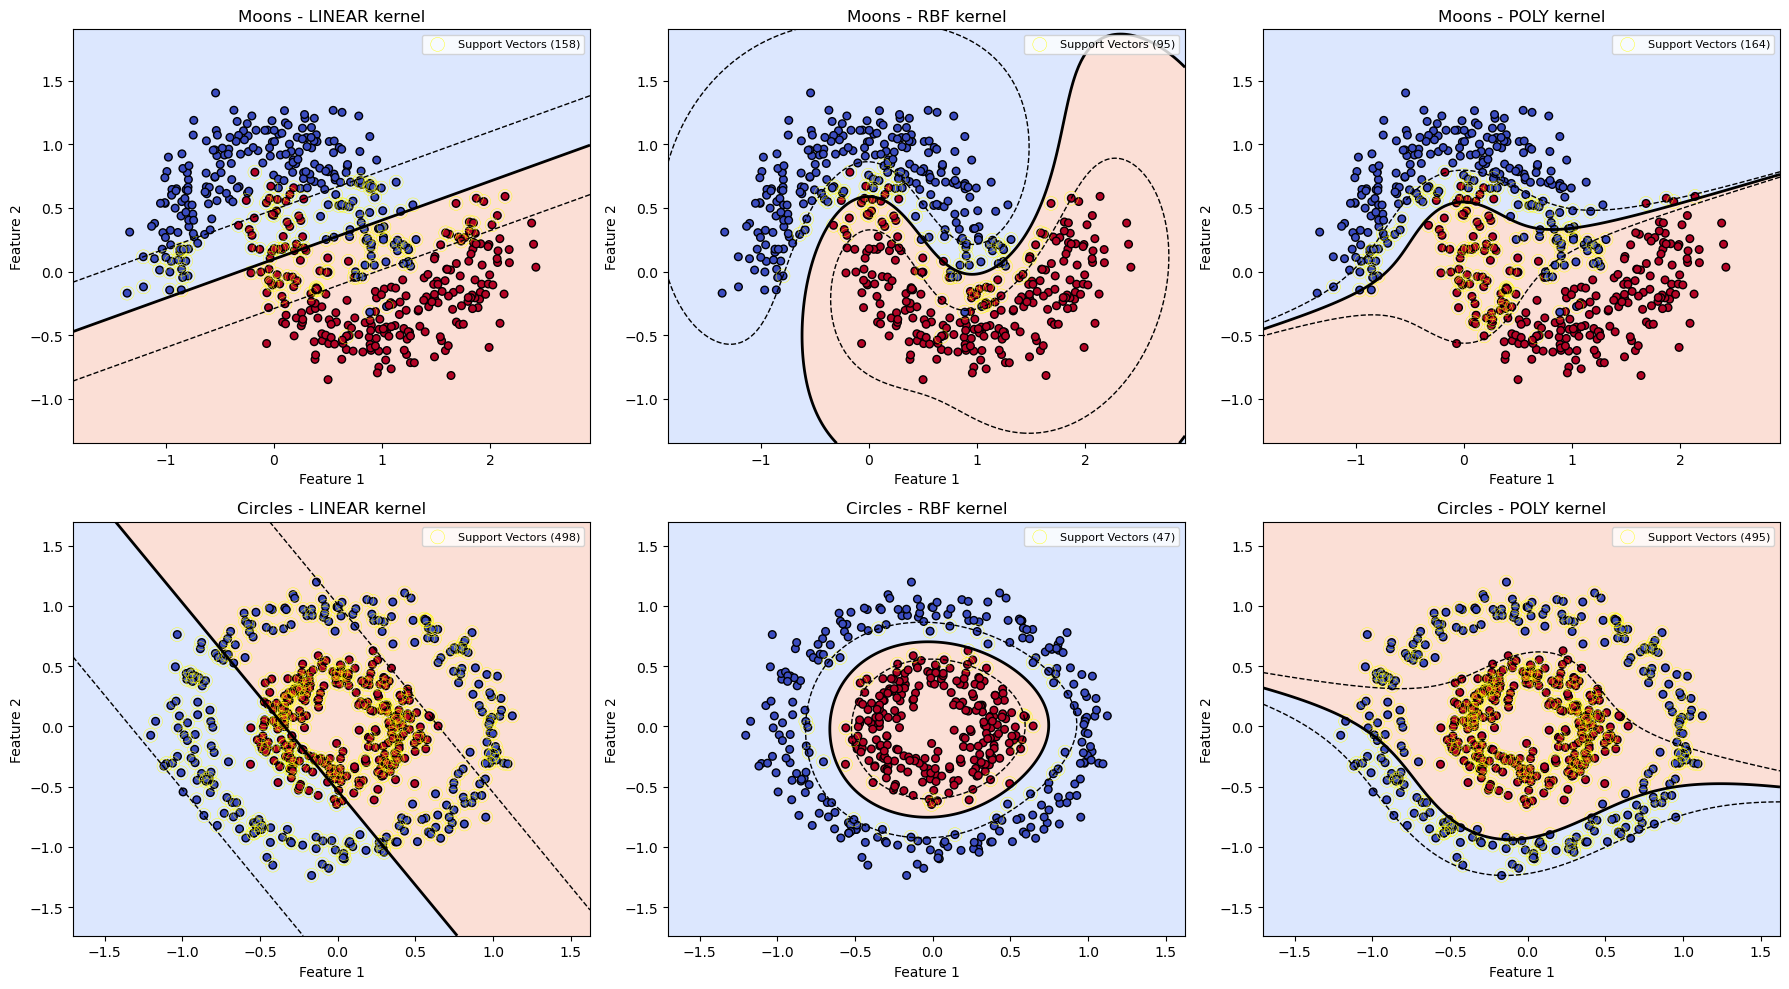

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

datasets = [
    ('Moons', X_moons, y_moons),
    ('Circles', X_circles, y_circles)
]
kernels = ['linear', 'rbf', 'poly']

for row, (name, X, y) in enumerate(datasets):
    for col, kernel in enumerate(kernels):

        ax = axes[row, col]
        accuracy, n_sv = plot_svm_boundary(
            X, y,
            kernel=kernel,
            C=1.0,
            ax=ax,
            title=f'{name} - {kernel.upper()} kernel'
        )
        print(f">>> [{name}, {kernel}] "
              f"Accuracy: {accuracy:.4f} | "
              f"Support Vectors: {n_sv}")

plt.tight_layout()
plt.show()


*[Your written response here]*

## 3b: SVM on Real Data with Hyperparameter Tuning (10 Points)

Now apply SVMs to a real-world classification task using the breast cancer dataset:

```py
# Dataset Loading - DO NOT MODIFY
bc_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data'
bc_columns = ['Sample_ID', 'Clump_Thickness', 'Uniformity_Cell_Size', 'Uniformity_Cell_Shape',
              'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
              'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class']
bc_data = pd.read_csv(bc_url, names=bc_columns, na_values='?').dropna()
X_bc = bc_data.drop(columns=['Sample_ID', 'Class']).values.astype(float)
y_bc = (bc_data['Class'].values == 4).astype(int)  # 1 = malignant, 0 = benign

# Standardize and split
scaler_bc = StandardScaler()
X_bc_scaled = scaler_bc.fit_transform(X_bc)
X_bc_train, X_bc_test, y_bc_train, y_bc_test = train_test_split(X_bc_scaled, y_bc, test_size=0.2)

print(f"Dataset shape: {X_bc.shape}")
print(f"Class distribution: {np.bincount(y_bc)}")
```

Perform a grid search over the following hyperparameters using 5-fold cross-validation (use `sklearn.model_selection.KFold` with `n_splits=5, shuffle=True`):
- `C` in `[0.01, 0.1, 1.0, 10.0, 100.0]`
- `kernel` in `['linear', 'rbf', 'poly']`
- For each fold, fit an `SVC` and compute the accuracy on the validation fold.

Record the mean CV accuracy for each (C, kernel) combination. Print the results as a table and identify the best combination:

```py
>>> Grid Search Results:
>>>           linear    rbf      poly
>>> C=0.01    X.XXXX   X.XXXX   X.XXXX
>>> C=0.1     X.XXXX   X.XXXX   X.XXXX
>>> ...
>>> Best: C=XX.X, kernel=XXXX -> CV Accuracy: X.XXXX
```

Train a final model with the best hyperparameters on the full training set and report the test accuracy:
```py
>>> Final Test Accuracy: X.XXXX
```

### Implementation Guide 3b

1. **Define hyperparameters:** Use 5 values of $C$ and 3 kernels, giving $5\times3=15$ combinations.
2. **Initialize:** Create `cv_accuracy_grid` with shape `(5, 3)` to store mean validation accuracy.
3. **Split:** Use `KFold(n_splits=5, shuffle=True)` to generate 5 training/validation splits.
4. **Train:** For each $(C,\text{kernel})$ combination, initialize a fresh `SVC()` and fit it on each training fold.
5. **Evaluate:** Calculate validation accuracy:
   $$\text{Accuracy}=\frac{\text{Number of Correct Predictions}}{\text{Total Predictions}}$$
6. **Average:** Compute the mean accuracy across 5 folds:
   $$\text{CV Accuracy}=\frac{1}{5}\sum_{k=1}^{5}\text{Accuracy}_k$$
7. **Select:** Use `np.argmax()` and `np.unravel_index()` to identify the best combination.
8. **Retrain and test:** Fit a final SVM on the full training set using the best hyperparameters, then evaluate test accuracy.

**Coding decisions:**
- Use nested loops to explore all hyperparameter combinations.
- Use `KFold` with a fixed random state for reproducible splits.
- Use `SVC(C=C, kernel=kernel)` with default kernel-specific settings.
- Use `accuracy_score()` to evaluate each validation fold.
- Use `pd.DataFrame()` to display the results as a formatted table.
- Keep the test set separate from hyperparameter selection.


In [65]:
# Define hyperparameters
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
kernels = ['linear', 'rbf', 'poly']

# Initialize accuracy grid
cv_accuracy_grid = np.zeros((len(C_values), len(kernels)))

# 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True)

for i, C in enumerate(C_values):
    for j, kernel in enumerate(kernels):

        fold_accuracies = []

        for train_idx, val_idx in kf.split(X_bc_train):

            # Split into training and validation folds
            X_tr = X_bc_train[train_idx]
            y_tr = y_bc_train[train_idx]
            X_val = X_bc_train[val_idx]
            y_val = y_bc_train[val_idx]

            # Train SVM
            model = SVC(C=C, kernel=kernel)
            model.fit(X_tr, y_tr)

            # Validation accuracy
            y_pred = model.predict(X_val)
            accuracy = accuracy_score(y_val, y_pred)

            fold_accuracies.append(accuracy)

        # Mean CV accuracy
        cv_accuracy_grid[i, j] = np.mean(fold_accuracies)

# Print grid search results as a table
print(">>> Grid Search Results:")

results_df = pd.DataFrame(
    cv_accuracy_grid,
    index=[f"C={C}" for C in C_values],
    columns=kernels
)
print(results_df.to_string(float_format=lambda x: f"{x:.4f}"))

# Find best hyperparameters
best_idx = np.unravel_index(
    np.argmax(cv_accuracy_grid),
    cv_accuracy_grid.shape
)
best_C = C_values[best_idx[0]]
best_kernel = kernels[best_idx[1]]
best_cv_accuracy = cv_accuracy_grid[best_idx]

print(f"\n>>> Best: C={best_C:.2f}, kernel={best_kernel} "
      f"-> CV Accuracy: {best_cv_accuracy:.4f}")

>>> Grid Search Results:
         linear    rbf   poly
C=0.01   0.9744 0.9469 0.8297
C=0.1    0.9725 0.9707 0.9249
C=1.0    0.9670 0.9743 0.9506
C=10.0   0.9707 0.9707 0.9578
C=100.0  0.9725 0.9597 0.9542

>>> Best: C=0.01, kernel=linear -> CV Accuracy: 0.9744


In [66]:
# Train final model
best_svm = SVC(C=best_C, kernel=best_kernel)
best_svm.fit(X_bc_train, y_bc_train)

# Predict on test set
y_bc_pred = best_svm.predict(X_bc_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_bc_test, y_bc_pred)

print(f">>> Final Test Accuracy: {test_accuracy:.4f}")

>>> Final Test Accuracy: 0.9562


## 3c: Classification Diagnostics (10 Points)

Using the best SVM model from 3b, produce a comprehensive set of classification diagnostics on the **test set**.

You will produce a single figure with 3 subplots:

**Subplot 1: Confusion Matrix**
- Use `sklearn.metrics.confusion_matrix` to compute the confusion matrix.
- Display it as a heatmap with `plt.imshow`, annotated with the counts in each cell.
- Label axes as "Predicted" and "Actual" with class names ["Benign", "Malignant"].

**Subplot 2: ROC Curve**
- Use `model.decision_function(X_test)` to get the raw scores.
- Compute and plot the ROC curve using `sklearn.metrics.roc_curve`.
- Shade the area under the curve and display the AUC in the legend.
- Plot the diagonal dashed line representing random chance.

**Subplot 3: Precision-Recall Curve**
- Compute and plot the precision-recall curve using `sklearn.metrics.precision_recall_curve`.
- Display the average precision (AP) in the legend.

Below the plots, print the full classification report using `sklearn.metrics.classification_report`.

Feel free to consult the following plotting code:
```py
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Confusion Matrix
cm = confusion_matrix(y_bc_test, y_pred)
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Benign', 'Malignant'])
axes[0].set_yticklabels(['Benign', 'Malignant'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=16)

# Subplot 2: ROC Curve
scores = best_model.decision_function(X_bc_test)
fpr, tpr, _ = roc_curve(y_bc_test, scores)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].fill_between(fpr, tpr, alpha=0.2, color='darkorange')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Chance')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

# Subplot 3: Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_bc_test, scores)
ap = np.trapz(precision, recall)  # Approximate AP
axes[2].plot(recall, precision, color='tab:green', lw=2, label=f'PR curve (AP = {abs(ap):.4f})')
axes[2].fill_between(recall, precision, alpha=0.2, color='tab:green')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend()

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(y_bc_test, y_pred, target_names=['Benign', 'Malignant']))
```

For full credit, write 4-5 sentences analyzing the diagnostic plots. Address the following:
- What do the confusion matrix values tell you about the model's strengths and weaknesses?
- What does the AUC tell you about the model's discriminative ability?
- In a medical diagnosis context, which type of error (false positive vs. false negative) is more dangerous, and how does your model perform on that metric?

### Implementation Guide 3c

1. **Predict:** Use `best_svm.predict(X_bc_test)` for class predictions and `decision_function()` for continuous decision scores.
2. **Confusion matrix:** Compute `confusion_matrix(y_bc_test, y_pred)` and visualize using `imshow()`.
   - **TN:** Benign correctly predicted as benign.
   - **FP:** Benign incorrectly predicted as malignant.
   - **FN:** Malignant incorrectly predicted as benign.
   - **TP:** Malignant correctly predicted as malignant.
3. **ROC curve:** Use `roc_curve()` to compute False Positive Rate (FPR) and True Positive Rate (TPR):
   $$\text{FPR}=\frac{FP}{FP+TN},\qquad \text{TPR}=\frac{TP}{TP+FN}$$
   Calculate AUC using `auc(fpr, tpr)`.
4. **Precision-Recall curve:** Use `precision_recall_curve()` and calculate Average Precision:
   $$AP=\sum_k(R_k-R_{k-1})P_k$$
   where $P_k$ and $R_k$ are precision and recall at successive thresholds ordered by increasing recall.
5. **Report:** Use `classification_report()` to display precision, recall, F1-score, and support for each class.
6. **Interpret:** Compare classification errors, ROC-AUC, and AP, emphasizing false negatives in medical diagnosis.

**Coding decisions:**
- Use `plt.subplots(1, 3)` for the three diagnostic plots.
- Use `imshow()` and `ax.text()` to display confusion matrix counts.
- Use `decision_function()` rather than predicted labels for ROC and PR curves.
- Use `auc()` for ROC-AUC and NumPy differences for AP.
- Use `fill_between()` to shade the areas under the curves.
- Treat malignant (class 1) as the positive class.


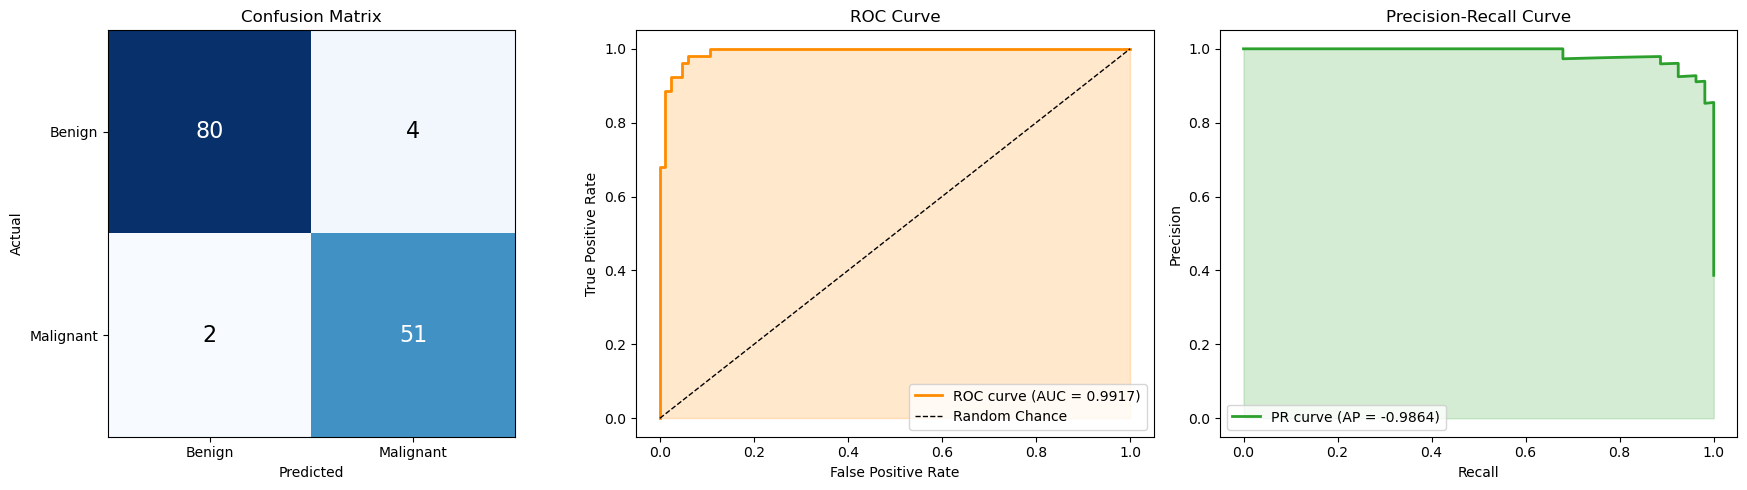


Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.95      0.96        84
   Malignant       0.93      0.96      0.94        53

    accuracy                           0.96       137
   macro avg       0.95      0.96      0.95       137
weighted avg       0.96      0.96      0.96       137



In [67]:
# Predictions and decision scores from best model in 3b
y_pred = best_svm.predict(X_bc_test)
scores = best_svm.decision_function(X_bc_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Confusion Matrix
cm = confusion_matrix(y_bc_test, y_pred)

im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Benign', 'Malignant'])
axes[0].set_yticklabels(['Benign', 'Malignant'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

for i in range(2):
    for j in range(2):
        axes[0].text(
            j, i, str(cm[i, j]),
            ha='center', va='center',
            color='white' if cm[i, j] > cm.max()/2 else 'black',
            fontsize=16
        )

# Subplot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_bc_test, scores)
roc_auc = auc(fpr, tpr)

axes[1].plot(
    fpr, tpr, color='darkorange', lw=2,
    label=f'ROC curve (AUC = {roc_auc:.4f})'
)
axes[1].fill_between(fpr, tpr, alpha=0.2, color='darkorange')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random Chance')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

# Subplot 3: Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_bc_test, scores)

# Average Precision (AP), using step-wise integration
# ap = -np.sum(np.diff(recall) * precision[:-1])
ap = np.trapz(precision, recall)  # Approximate AP

axes[2].plot(
    recall, precision, color='tab:green', lw=2,
    label=f'PR curve (AP = {ap:.4f})'
)
axes[2].fill_between(recall, precision, alpha=0.2, color='tab:green')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend()

plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_bc_test, y_pred,
    target_names=['Benign', 'Malignant']
))


*[Your written response here]*